In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ds = pd.read_csv("data set/ApexPlanet_DataAnalytics_Dataset2.csv")

In [3]:
df = ds.copy()

In [4]:
print(df)

      Order_ID  Order_Date Customer_ID Customer_Name   Age  Gender       City  \
0    ORD100002  2025-02-25    CUST5529  Customer_227  30.0  Female  Bengaluru   
1    ORD100003  2025-10-14    CUST3127  Customer_182  63.0    Male  Bengaluru   
2    ORD100004  2025-05-13    CUST8887  Customer_487  62.0  Female  Bengaluru   
3    ORD100005  2025-12-02    CUST2515  Customer_470  65.0  Female    Kolkata   
4    ORD100006  2025-11-20    CUST4796  Customer_380  44.0    Male  Bengaluru   
..         ...         ...         ...           ...   ...     ...        ...   
995  ORD100997  2025-11-07    CUST6410  Customer_301  61.0    Male       Gaya   
996  ORD100998  2025-09-03    CUST7618  Customer_154  25.0    Male       Gaya   
997  ORD100999  2025-09-30    CUST9544  Customer_140  62.0  Female  Hyderabad   
998  ORD101000  2025-02-21    CUST9501  Customer_241   NaN    Male      Delhi   
999  ORD101001  2025-04-23    CUST2714   Customer_98  58.0  Female       Gaya   

    Product     Category  Q

In [5]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [6]:
df.tail()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
995,ORD100997,2025-11-07,CUST6410,Customer_301,61.0,Male,Gaya,Laptop,Electronics,9,35405.54,318649.86
996,ORD100998,2025-09-03,CUST7618,Customer_154,25.0,Male,Gaya,Shoes,Fashion,5,18454.65,92273.25
997,ORD100999,2025-09-30,CUST9544,Customer_140,62.0,Female,Hyderabad,Laptop,Electronics,9,12971.59,116744.31
998,ORD101000,2025-02-21,CUST9501,Customer_241,NaN,Male,Delhi,Mobile,Electronics,9,2879.01,25911.09
999,ORD101001,2025-04-23,CUST2714,Customer_98,58.0,Female,Gaya,Chair,Furniture,9,22493.87,202444.83


In [7]:
df.shape

(1000, 12)

In [8]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age',
       'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price',
       'Total_Sales'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB


data cleaning 

In [11]:
df.isnull().sum()

Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name     0
Age              20
Gender            0
City             13
Product           0
Category          0
Quantity          0
Unit_Price        0
Total_Sales       0
dtype: int64

In [12]:
print(ds.shape)

(1000, 12)


In [13]:
print(df.duplicated(subset=["Order_ID"]).sum())

8


Removeing duplicates to get distinct rows

In [15]:
df.drop_duplicates(subset=["Order_ID"],keep=False,inplace=True)

In [16]:
print(df.shape)

(991, 12)


In [17]:
df.isna().sum()

Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name     0
Age              18
Gender            0
City             12
Product           0
Category          0
Quantity          0
Unit_Price        0
Total_Sales       0
dtype: int64

In [18]:
df["City"]=df["City"].fillna("N/A")

In [19]:
df.isna().sum()

Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name     0
Age              18
Gender            0
City              0
Product           0
Category          0
Quantity          0
Unit_Price        0
Total_Sales       0
dtype: int64

In [20]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [21]:
df.dtypes

Order_ID                 object
Order_Date       datetime64[ns]
Customer_ID              object
Customer_Name            object
Age                     float64
Gender                   object
City                     object
Product                  object
Category                 object
Quantity                  int64
Unit_Price              float64
Total_Sales             float64
dtype: object

**Adding Age group**

In [23]:
df["Age_Category"] = df["Age"].apply(
    lambda x: "Gen Z Adults" if x >= 18 and x <=24 
    else "Millennials" if x >= 25 and x <=34 
    else "Mid-Career" if x >= 35 and x <=44 
    else "Mature Professionals" if x >= 45 and x <=55 
    else "Pre-Retirement" if x >= 55 and x <=65 else "Unknown")

**Adding ordered months calomn**

In [25]:
df["Order_Month"]=df["Order_Date"].dt.month_name()
df["Month"] = df["Order_Date"].dt.month

**Average sales**

In [27]:
round(df["Total_Sales"].mean())

139079

**Maximum Sales**

In [29]:
round(df["Total_Sales"].max())

493678

**Minimum Sales**

In [31]:
round(df["Total_Sales"].min())

437

**Total Sales**

In [33]:
round(df["Total_Sales"].sum())

137826798

***Total sales by gender***

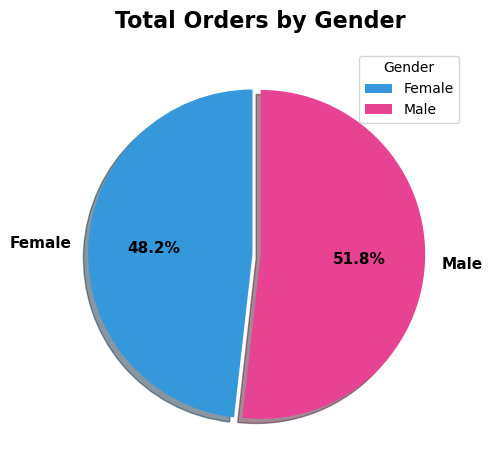

In [99]:
# Calculate sales by gender
sales = df.groupby("Gender")["Total_Sales"].sum()

# Assign different colors
colors = sales.index.map({
    "Male": "blue",
    "Female": "pink"
})

# bar chart
bars = plt.pie(
    sales.values,
    labels=sales.index,
    autopct="%1.1f%%",
    colors=["#3498DB", "#E84393"],
    startangle=90,
    explode=(0.05, 0),
    shadow=True,
    textprops={"fontsize": 11, "fontweight": "bold"}
)

plt.title(
    "Total Orders by Gender",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.legend(
    sales.index,
    title="Gender",
    loc="best"
)

plt.tight_layout()
plt.show()

# Format values into K, M, B
def format_value(value):
    if value >= 1_000_000_000:
        return f"{value/1_000_000_000:.1f}B"
    elif value >= 1_000_000:
        return f"{value/1_000_000:.1f}M"
    elif value >= 1000:
        return f"{value/1000:.1f}K"
    return str(int(value))



***Total sales by City***

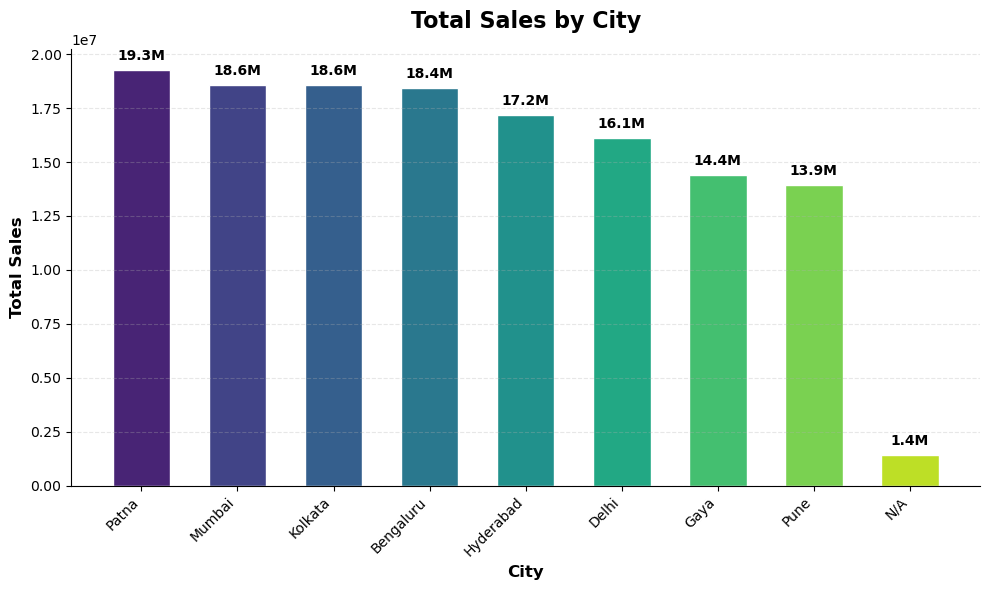

In [37]:
sales = df.groupby("City")["Total_Sales"].sum().sort_values(ascending=False)

# Different colors for each city
colors = sns.color_palette("viridis", len(sales))

# Create bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    sales.index,
    sales.values,
    color=colors,
    width=0.6,
    edgecolor="white"
)


labels = [format_value(v) for v in sales.values]

plt.bar_label(
    bars,
    labels=labels,
    padding=5,
    fontsize=10,
    fontweight="bold"
)

# Titles and labels
plt.xlabel("City", fontsize=12, fontweight="bold")
plt.ylabel("Total Sales", fontsize=12, fontweight="bold")

plt.title(
    "Total Sales by City",
    fontsize=16,
    fontweight="bold",
    pad=15
)

# Styling
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()

plt.show()

***Total sales by product***

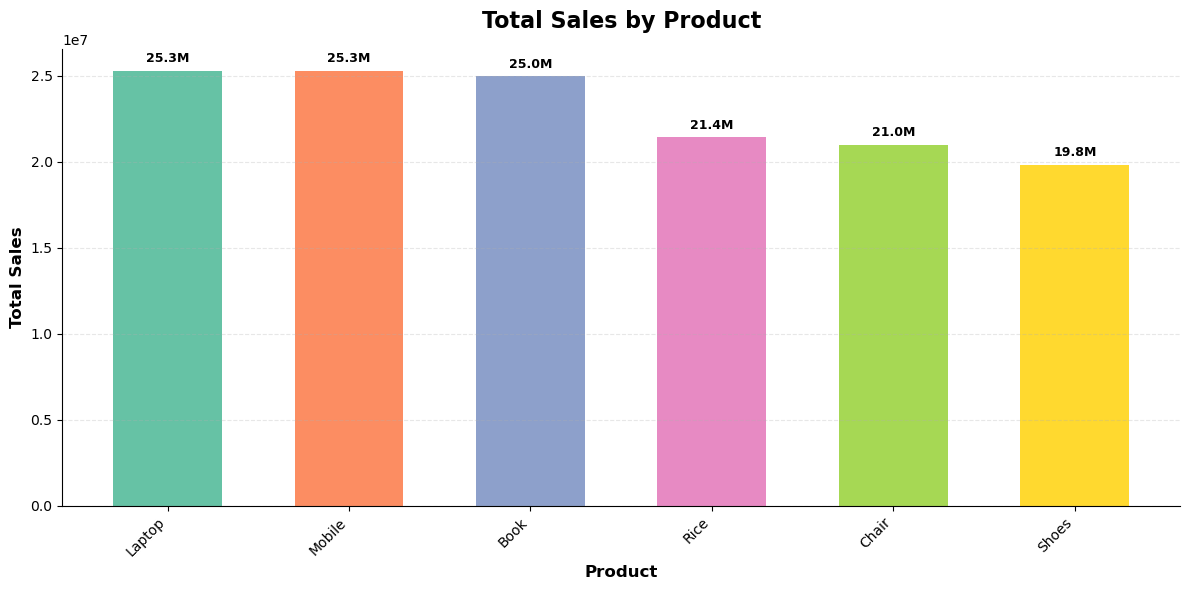

In [39]:

sales = df.groupby("Product")["Total_Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    sales.index,
    sales.values,
    color=sns.color_palette("Set2", len(sales)),
    width=0.6
)

plt.bar_label(
    bars,
    labels=[format_value(v) for v in sales.values],
    padding=4,
    fontsize=9,
    fontweight="bold"
)

plt.xlabel("Product", fontsize=12, fontweight="bold")
plt.ylabel("Total Sales", fontsize=12, fontweight="bold")

plt.title(
    "Total Sales by Product",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()


***Total sales by Order Month***

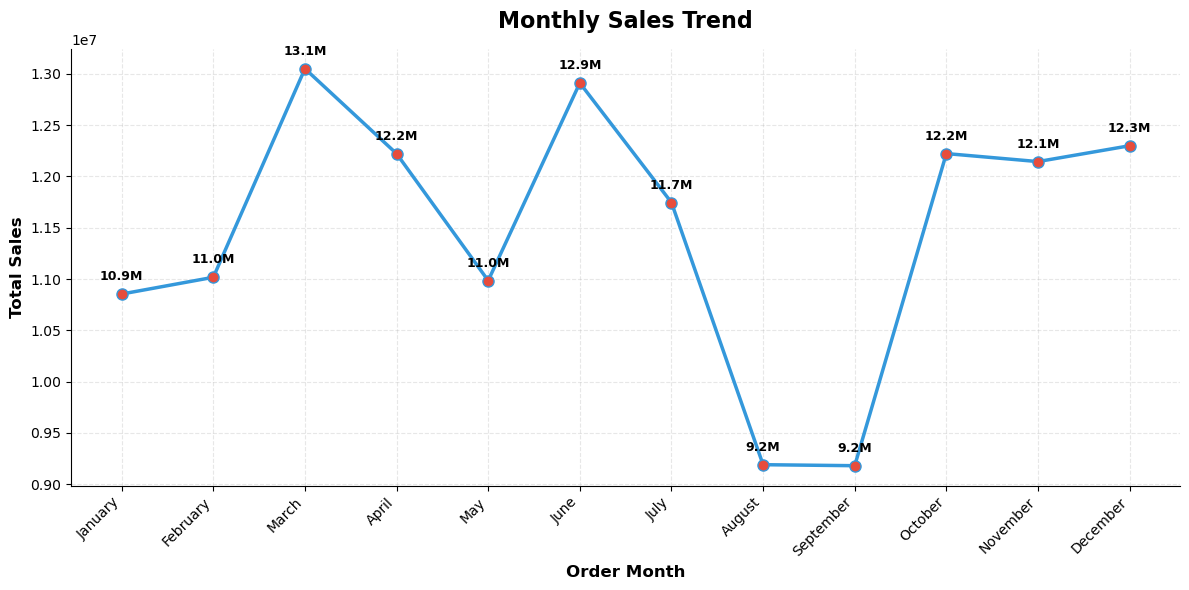

In [91]:

sales = df.groupby("Order_Month")["Total_Sales"].sum()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

sales = sales.reindex(month_order).dropna()

plt.figure(figsize=(12, 6))

plt.plot(
    sales.index,
    sales.values,
    color="#3498DB",
    marker="o",
    markersize=8,
    linewidth=2.5,
    markerfacecolor="#E74C3C"
)

# Add value labels
for i, value in enumerate(sales.values):
    plt.annotate(
        format_value(value),
        (i, value),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

plt.xlabel("Order Month", fontsize=12, fontweight="bold")
plt.ylabel("Total Sales", fontsize=12, fontweight="bold")

plt.title(
    "Monthly Sales Trend",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.grid(axis="both", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()


**Total sales by Age group**

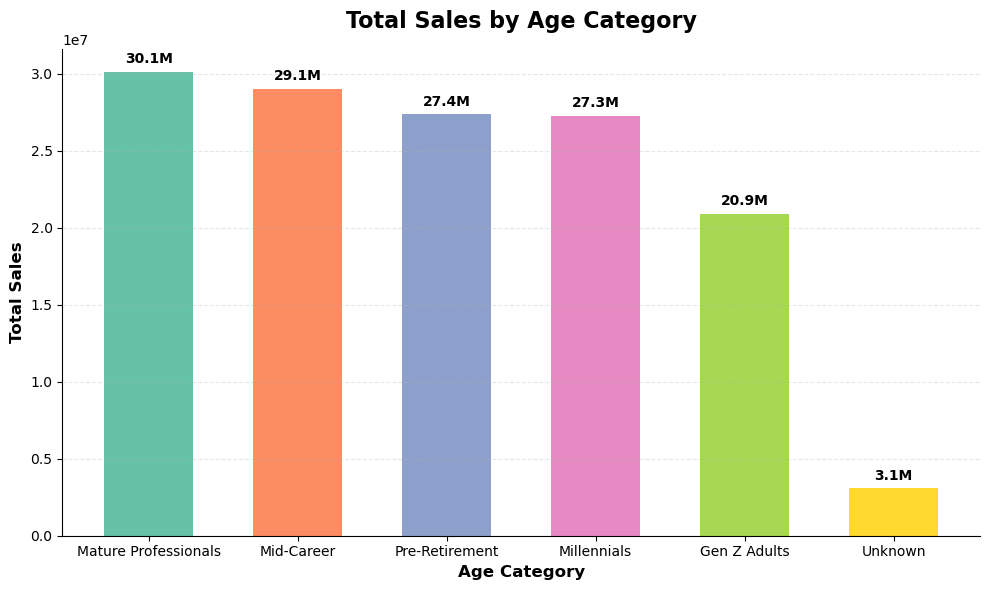

In [43]:

sales = df.groupby("Age_Category")["Total_Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    sales.index,
    sales.values,
    color=sns.color_palette("Set2", len(sales)),
    width=0.6
)

plt.bar_label(
    bars,
    labels=[format_value(v) for v in sales.values],
    padding=4,
    fontsize=10,
    fontweight="bold"
)

plt.xlabel("Age Category", fontsize=12, fontweight="bold")
plt.ylabel("Total Sales", fontsize=12, fontweight="bold")

plt.title(
    "Total Sales by Age Category",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()


***Total orders by order month***

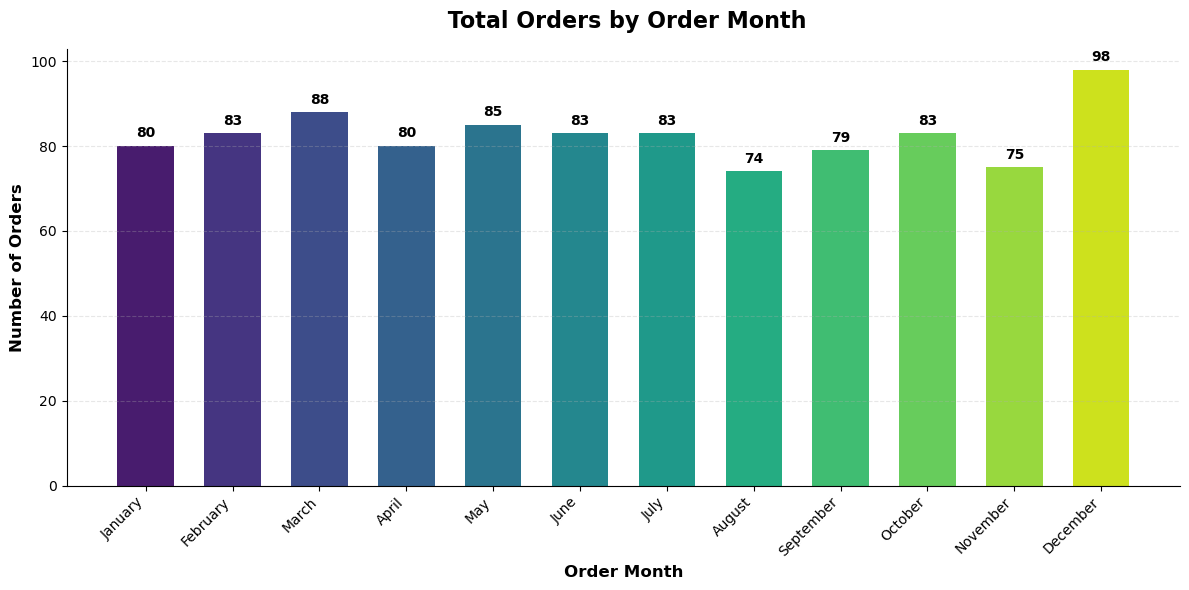

In [45]:

sales = df.groupby("Order_Month")["Order_ID"].nunique()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

sales = sales.reindex(month_order).dropna()

plt.figure(figsize=(12, 6))

bars = plt.bar(
    sales.index,
    sales.values,
    color=sns.color_palette("viridis", len(sales)),
    width=0.65
)

plt.bar_label(
    bars,
    padding=4,
    fontsize=10,
    fontweight="bold"
)

plt.xlabel("Order Month", fontsize=12, fontweight="bold")
plt.ylabel("Number of Orders", fontsize=12, fontweight="bold")

plt.title(
    " Total Orders by Order Month",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()


***Total orders by city***

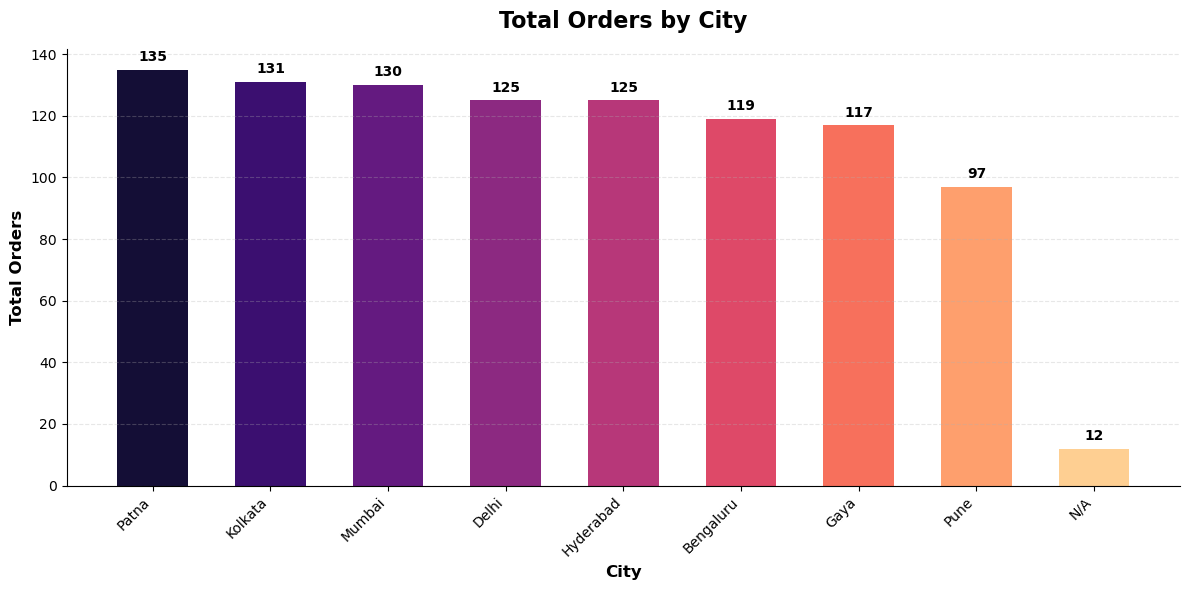

In [47]:

sales = df.groupby("City")["Order_ID"].nunique().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    sales.index,
    sales.values,
    color=sns.color_palette("magma", len(sales)),
    width=0.6
)

plt.bar_label(
    bars,
    padding=4,
    fontsize=10,
    fontweight="bold"
)

plt.xlabel("City", fontsize=12, fontweight="bold")
plt.ylabel("Total Orders", fontsize=12, fontweight="bold")

plt.title(
    "Total Orders by City",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()


***Total orders by Gender***

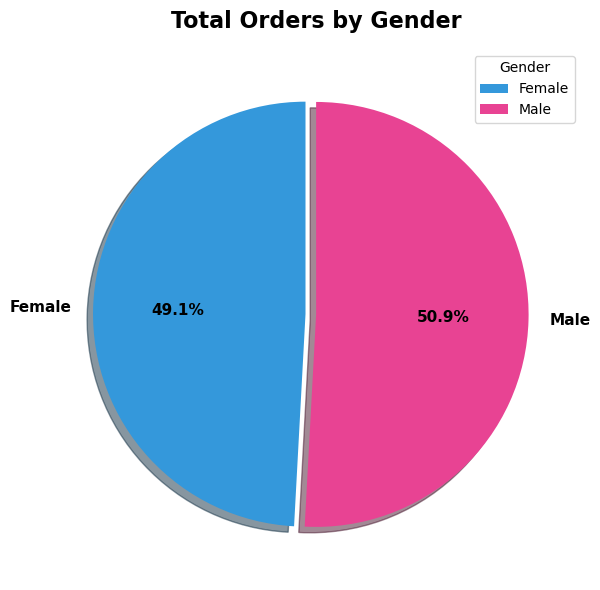

In [97]:

sales = df.groupby("Gender")["Order_ID"].nunique()

plt.figure(figsize=(8, 6))

bars = plt.pie(
    sales.values,
    labels=sales.index,
    autopct="%1.1f%%",
    colors=["#3498DB", "#E84393"],
    startangle=90,
    explode=(0.05, 0),
    shadow=True,
    textprops={"fontsize": 11, "fontweight": "bold"}
)

plt.title(
    "Total Orders by Gender",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.legend(
    sales.index,
    title="Gender",
    loc="best"
)

plt.tight_layout()
plt.show()




***Total order by age category***

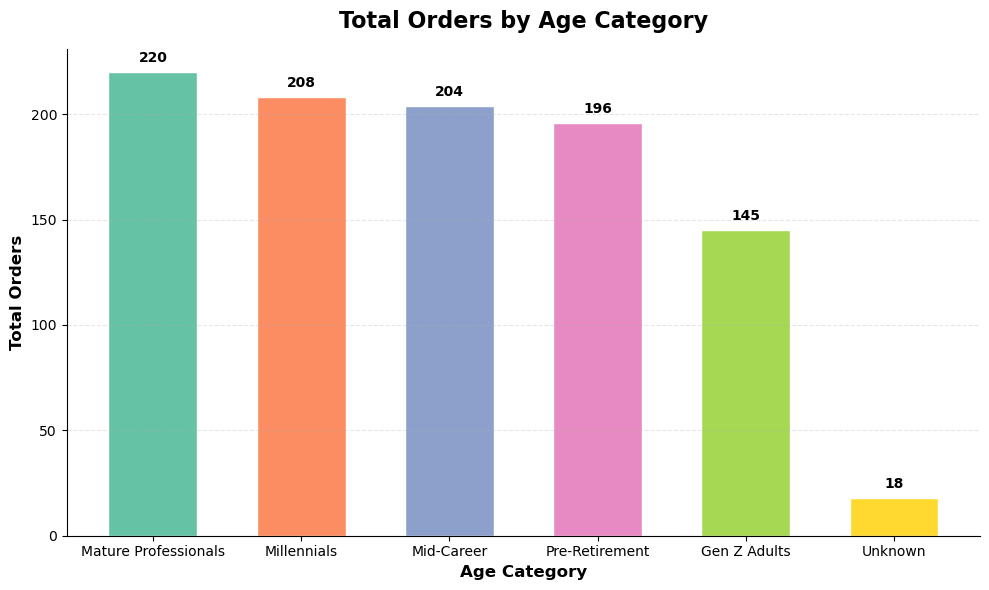

In [51]:

sales = df.groupby("Age_Category")["Order_ID"].nunique().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    sales.index,
    sales.values,
    color=sns.color_palette("Set2", len(sales)),
    width=0.6,
    edgecolor="white"
)

plt.bar_label(
    bars,
    padding=5,
    fontsize=10,
    fontweight="bold"
)

plt.xlabel("Age Category", fontsize=12, fontweight="bold")
plt.ylabel("Total Orders", fontsize=12, fontweight="bold")

plt.title(
    "Total Orders by Age Category",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.grid(axis="y", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()


***Top selling product***

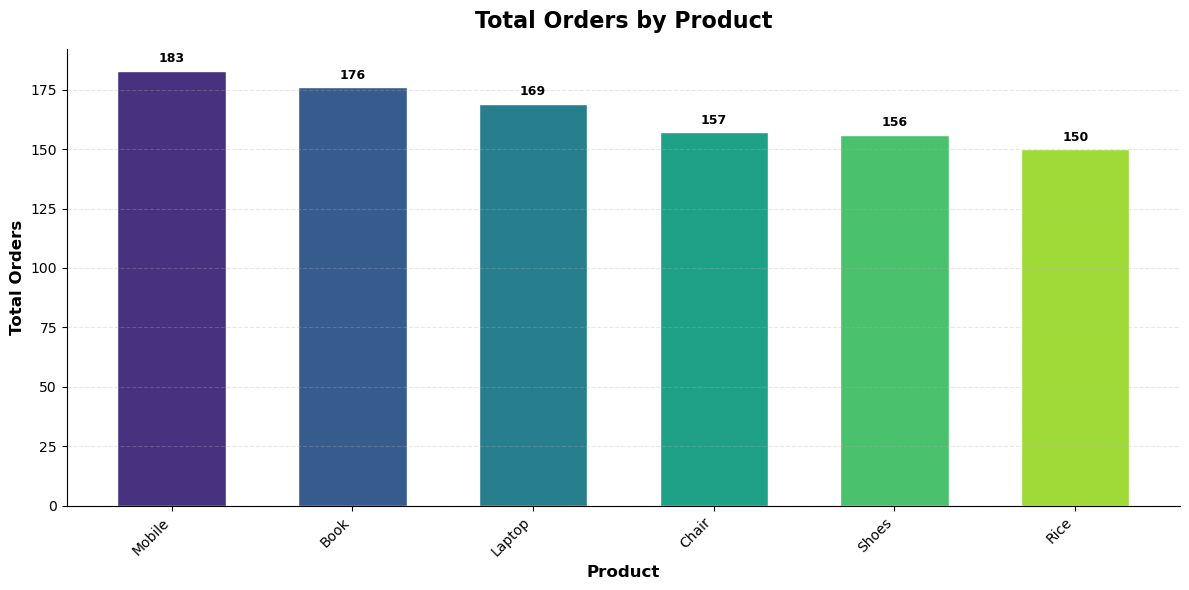

In [53]:

sales = df.groupby("Product")["Order_ID"].nunique().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

bars = plt.bar(
    sales.index,
    sales.values,
    color=sns.color_palette("viridis", len(sales)),
    width=0.6,
    edgecolor="white"
)

plt.bar_label(
    bars,
    padding=4,
    fontsize=9,
    fontweight="bold"
)

plt.xlabel("Product", fontsize=12, fontweight="bold")
plt.ylabel("Total Orders", fontsize=12, fontweight="bold")

plt.title(
    "Total Orders by Product",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()
